PHASE 1: DATA LOADING

In [1]:
# Import the pandas library
import pandas as pd

# Load the Titanic datasets
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
gender_submission = pd.read_csv("gender_submission.csv")

print("Datasets loaded successfully!")

print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)
print("Gender submission shape:", gender_submission.shape)



Datasets loaded successfully!
Training dataset shape: (891, 12)
Testing dataset shape: (418, 11)
Gender submission shape: (418, 2)


 Exploratory Data Analysis (EDA)

In [2]:
# Display the first five rows of the training dataset
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Check the dataset information

In [3]:
# Check the structure of the training dataset
train.info()

# Check for missing values in each column
print("\nMissing values in each column:")
print(train.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2

clearer missing-values summary

In [4]:
# Check missing values and percentages

missing_summary = pd.DataFrame({
    "Missing Values": train.isnull().sum(),
    "Percentage (%)": (train.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(by="Missing Values", ascending=False)

display(missing_summary)

,Missing Values,Percentage (%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


Data Cleaning

In [5]:
# Check missing values in both datasets

print("TRAINING DATASET")
print(train.isnull().sum()[train.isnull().sum() > 0])

print("\nTESTING DATASET")
print(test.isnull().sum()[test.isnull().sum() > 0])

TRAINING DATASET
Age         177
Cabin       687
Embarked      2
dtype: int64

TESTING DATASET
Age       86
Fare       1
Cabin    327
dtype: int64


In [6]:
# Step 1: Calculate values from training data

age_median = train["Age"].median()
fare_median = train["Fare"].median()
embarked_mode = train["Embarked"].mode()[0]

# Step 2: Clean both datasets

for df in [train, test]:

    # Fill missing Age
    df["Age"] = df["Age"].fillna(age_median)

    # Fill missing Fare
    df["Fare"] = df["Fare"].fillna(fare_median)

    # Fill missing Embarked
    df["Embarked"] = df["Embarked"].fillna(embarked_mode)

    # Create a feature showing cabin availability
    if "Cabin" in df.columns:
        df["HasCabin"] = df["Cabin"].notna().astype(int)
        df.drop(columns=["Cabin"], inplace=True)

print("Data cleaning completed!")

# Step 3: Check remaining missing values

print("\nTraining missing values:")
print(train.isnull().sum().sum())

print("\nTesting missing values:")
print(test.isnull().sum().sum())


Data cleaning completed!

Training missing values:
0

Testing missing values:
0


C:\Users\USER\AppData\Local\Temp\ipykernel_12200\3353837614.py:23: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Cabin"], inplace=True)
C:\Users\USER\AppData\Local\Temp\ipykernel_12200\3353837614.py:23: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Cabin"], inplace=True)


In [7]:
# Exploratory Data Analysis

# 1. Survival count
print("Survival Distribution:")
print(train["Survived"].value_counts())

# 2. Survival rate by gender
print("\nSurvival Rate by Gender (%):")
print(
    (train.groupby("Sex")["Survived"].mean() * 100).round(2)
)

# 3. Survival rate by passenger class
print("\nSurvival Rate by Passenger Class (%):")
print(
    (train.groupby("Pclass")["Survived"].mean() * 100).round(2)
)


Survival Distribution:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Rate by Gender (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Survival Rate by Passenger Class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


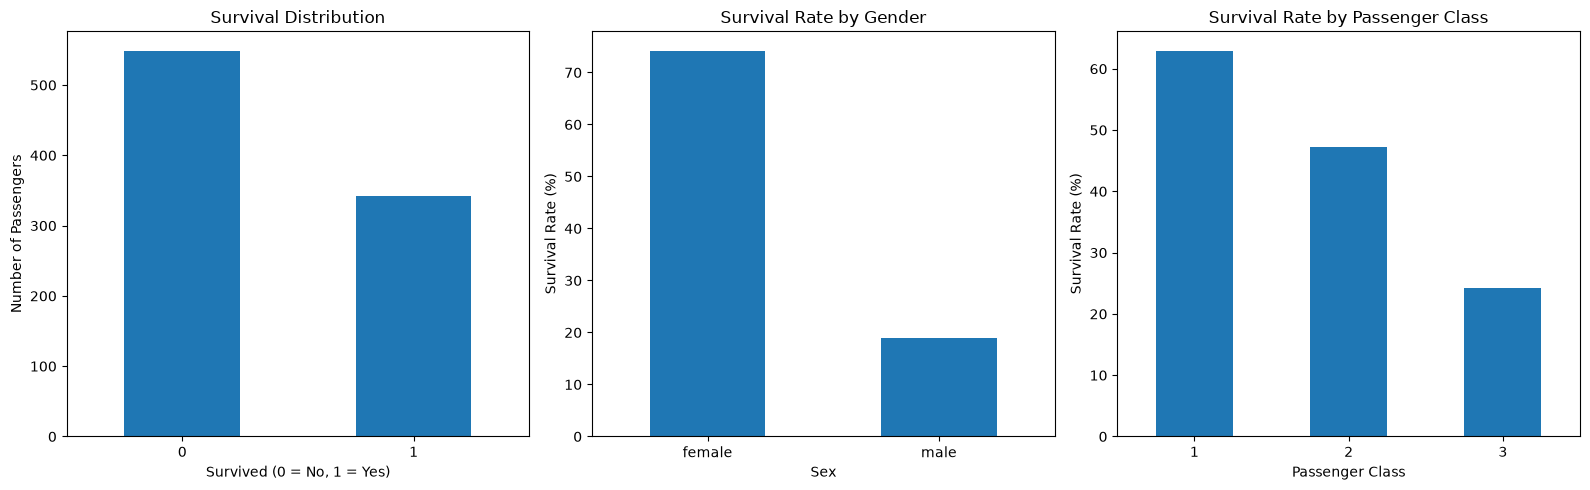

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Survival distribution
train["Survived"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Survival Distribution")
axes[0].set_xlabel("Survived (0 = No, 1 = Yes)")
axes[0].set_ylabel("Number of Passengers")
axes[0].tick_params(axis="x", rotation=0)

# 2. Survival by gender
gender_survival = train.groupby("Sex")["Survived"].mean() * 100
gender_survival.plot(kind="bar", ax=axes[1])
axes[1].set_title("Survival Rate by Gender")
axes[1].set_ylabel("Survival Rate (%)")
axes[1].tick_params(axis="x", rotation=0)

# 3. Survival by passenger class
class_survival = train.groupby("Pclass")["Survived"].mean() * 100
class_survival.plot(kind="bar", ax=axes[2])
axes[2].set_title("Survival Rate by Passenger Class")
axes[2].set_xlabel("Passenger Class")
axes[2].set_ylabel("Survival Rate (%)")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


In [9]:
# Feature Engineering: Family Information

for df in [train, test]:

    # Calculate total family size
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

    # Identify passengers travelling alone
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

print("Family features created successfully!")

# Display the new features
display(train[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10))


Family features created successfully!


,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0


In [10]:
# Feature Engineering: Extract Passenger Titles

for df in [train, test]:

    # Extract titles from passenger names
    df["Title"] = df["Name"].str.extract(
        r",\s*([^.]*)\."
    )

print("Passenger titles extracted successfully!")

# Display passenger names and their titles
display(train[["Name", "Title"]].head(10))

Passenger titles extracted successfully!


,Name,Title
0,"Braund, Mr. Owen Harris",Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs
2,"Heikkinen, Miss. Laina",Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs
4,"Allen, Mr. William Henry",Mr
5,"Moran, Mr. James",Mr
6,"McCarthy, Mr. Timothy J",Mr
7,"Palsson, Master. Gosta Leonard",Master
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs
9,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs


In [11]:
# Count the different passenger titles
print("Passenger Title Distribution:")
print(train["Title"].value_counts())

Passenger Title Distribution:
Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


In [12]:
# Step 1: Replace similar passenger titles
for df in [train, test]:

    df["Title"] = df["Title"].replace({
        "Mlle": "Miss",
        "Ms": "Miss",
        "Mme": "Mrs"
    })

    # Step 2: Group uncommon titles as Rare
    df["Title"] = df["Title"].replace([
        "Dr", "Rev", "Major", "Col", "Don",
        "Lady", "Sir", "Capt", "the Countess",
        "Jonkheer"
    ], "Rare")


# Step 3: Display the updated title distribution
print("Titles grouped successfully!")

print("\nUpdated Passenger Title Distribution:")
print(train["Title"].value_counts())

Titles grouped successfully!

Updated Passenger Title Distribution:
Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


In [13]:
# Save PassengerId for our final submission
test_passenger_ids = test["PassengerId"]

# Remove unnecessary columns
train = train.drop(columns=["Name", "Ticket", "PassengerId"])
test = test.drop(columns=["Name", "Ticket", "PassengerId"])

print("Unnecessary columns removed successfully!")

print("\nTraining dataset columns:")
print(train.columns.tolist())

print("\nTest dataset columns:")
print(test.columns.tolist())

Unnecessary columns removed successfully!

Training dataset columns:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'HasCabin', 'FamilySize', 'IsAlone', 'Title']

Test dataset columns:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'HasCabin', 'FamilySize', 'IsAlone', 'Title']


In [14]:
# Separate the target variable from the training data

X = train.drop(columns=["Survived"])
y = train["Survived"]

# Check the results
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features (X) shape: (891, 11)
Target (y) shape: (891,)

Feature columns:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'HasCabin', 'FamilySize', 'IsAlone', 'Title']


In [15]:
# Convert categorical columns into numerical columns

X = pd.get_dummies(
    X,
    columns=["Sex", "Embarked", "Title"],
    dtype=int
)

test_encoded = pd.get_dummies(
    test,
    columns=["Sex", "Embarked", "Title"],
    dtype=int
)

# Make sure training and test data have the same columns
test_encoded = test_encoded.reindex(
    columns=X.columns,
    fill_value=0
)

print("Categorical encoding completed successfully!")

print("\nTraining data shape:", X.shape)
print("Test data shape:", test_encoded.shape)

print("\nEncoded feature columns:")
print(X.columns.tolist())

Categorical encoding completed successfully!

Training data shape: (891, 18)
Test data shape: (418, 18)

Encoded feature columns:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'HasCabin', 'FamilySize', 'IsAlone', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


In [17]:
# Import the train_test_split function
from sklearn.model_selection import train_test_split

# Split the training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the sizes of our new datasets
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

Training features: (712, 18)
Validation features: (179, 18)
Training labels: (712,)
Validation labels: (179,)


In [18]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model using our training data
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [20]:
# Make predictions using the validation data
y_pred = model.predict(X_val)

# Import accuracy_score
from sklearn.metrics import accuracy_score

# Calculate model accuracy
accuracy = accuracy_score(y_val, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")


Model Accuracy: 83.24 %


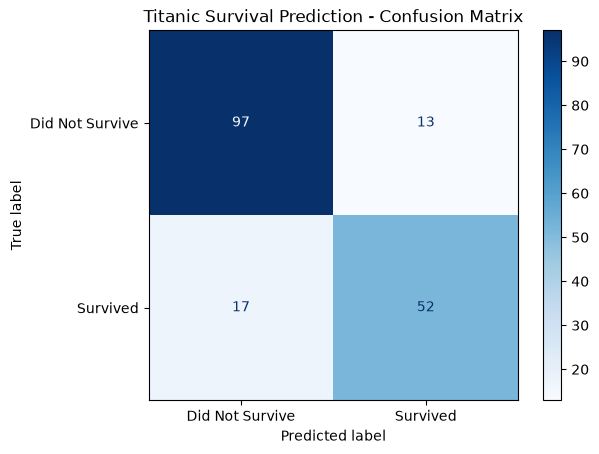

In [21]:
# Import confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_val, y_pred)

# Display the confusion matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

display_matrix.plot(cmap="Blues")
plt.title("Titanic Survival Prediction - Confusion Matrix")
plt.show()

In [22]:
# Import classification report
from sklearn.metrics import classification_report

# Generate the model performance report
report = classification_report(
    y_val,
    y_pred,
    target_names=["Did Not Survive", "Survived"]
)

# Display the report
print(report)

                 precision    recall  f1-score   support

Did Not Survive       0.85      0.88      0.87       110
       Survived       0.80      0.75      0.78        69

       accuracy                           0.83       179
      macro avg       0.83      0.82      0.82       179
   weighted avg       0.83      0.83      0.83       179



In [23]:
# Import Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [24]:
# Make predictions using Random Forest
rf_predictions = rf_model.predict(X_val)

# Calculate Random Forest accuracy
rf_accuracy = accuracy_score(y_val, rf_predictions)

# Display the accuracy
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 80.45 %


In [25]:
# Generate Random Forest classification report
print(classification_report(
    y_val,
    rf_predictions,
    target_names=["Did Not Survive", "Survived"]
))


                 precision    recall  f1-score   support

Did Not Survive       0.84      0.84      0.84       110
       Survived       0.74      0.75      0.75        69

       accuracy                           0.80       179
      macro avg       0.79      0.79      0.79       179
   weighted avg       0.81      0.80      0.80       179



In [26]:
# Create an improved Random Forest model
rf_tuned = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_split=5,
    random_state=42
)

# Train the improved model
rf_tuned.fit(X_train, y_train)

print("Improved Random Forest model trained successfully!")


Improved Random Forest model trained successfully!


In [27]:
# Make predictions using the improved model
rf_tuned_predictions = rf_tuned.predict(X_val)

# Calculate its accuracy
rf_tuned_accuracy = accuracy_score(
    y_val,
    rf_tuned_predictions
)

# Display the result
print(
    "Improved Random Forest Accuracy:",
    round(rf_tuned_accuracy * 100, 2),
    "%"
)


Improved Random Forest Accuracy: 82.12 %


In [28]:
# Generate classification report for improved Random Forest

print(classification_report(
    y_val,
    rf_tuned_predictions,
    target_names=["Did Not Survive", "Survived"]
))

                 precision    recall  f1-score   support

Did Not Survive       0.84      0.87      0.86       110
       Survived       0.78      0.74      0.76        69

       accuracy                           0.82       179
      macro avg       0.81      0.81      0.81       179
   weighted avg       0.82      0.82      0.82       179



In [29]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create our final model
final_model = LogisticRegression(max_iter=1000)

# Train using the entire training dataset
final_model.fit(X, y)

print("Final model trained successfully!")

Final model trained successfully!


In [30]:
# Predict survival for the test dataset
test_predictions = final_model.predict(test_encoded)

# Display the first 10 predictions
print("First 10 survival predictions:")
print(test_predictions[:10])

# Count the predicted survival outcomes
print("\nPrediction distribution:")
print(pd.Series(test_predictions).value_counts())

First 10 survival predictions:
[0 1 0 0 1 0 1 0 1 0]

Prediction distribution:
0    252
1    166
Name: count, dtype: int64


In [31]:
# Create the submission dataframe
submission = pd.DataFrame({
    "PassengerId": test_passenger_ids,
    "Survived": test_predictions
})

# Save the submission as a CSV file
submission.to_csv("submission.csv", index=False)

print("Kaggle submission file created successfully!")

# Display the first 10 rows
display(submission.head(10))

Kaggle submission file created successfully!


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


In [32]:
# Read the saved submission file
check_submission = pd.read_csv("submission.csv")

print("Submission shape:", check_submission.shape)

print("\nSubmission columns:")
print(check_submission.columns.tolist())

print("\nMissing values:")
print(check_submission.isnull().sum())

display(check_submission.head(10))

Submission shape: (418, 2)

Submission columns:
['PassengerId', 'Survived']

Missing values:
PassengerId    0
Survived       0
dtype: int64


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0
